## Loading the Dataset


In [1]:
# Day 16 – Cell 1
# Imports and device setup

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


In [2]:
# Day 16 – Cell 2
# Dataset path

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"

V1_PATH = os.path.join(
    DATASET_PATH,
    "processed_dataset_v1"
)

print("Dataset path:")
print(V1_PATH)

Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1


In [3]:
# Day 16 – Cell 2
# Mount Drive and verify dataset path

from google.colab import drive
import os

drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/IITG dataset/cleaned_dataset"
V1_PATH = os.path.join(DATASET_PATH, "processed_dataset_v1")

print("Checking path:")
print(V1_PATH)

print("\nFiles inside processed_dataset_v1:")

if os.path.exists(V1_PATH):
    print(os.listdir(V1_PATH))
else:
    print("processed_dataset_v1 folder NOT FOUND")

Mounted at /content/drive
Checking path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1

Files inside processed_dataset_v1:
['sequences_v1.npz', 'processing_info_v1.json', 'feature_scaler_v1.pkl', 'gru_best_model.pth', 'tcn_best_model.pth', 'lstm_best_model.pth', 'day16_gru_best_soh_model.pth', 'day15_lstm_best_soh_model.pth', 'day19_best_lstm.pth', 'day19_lstm_hyperparameter_results.csv', 'day17_tcn_best_soh_model.pth']


In [4]:
# Day 16 – Cell 3
# Load sequence dataset

SEQUENCES_PATH = os.path.join(
    V1_PATH,
    "sequences_v1.npz"
)

print("Loading:")
print(SEQUENCES_PATH)

data = np.load(
    SEQUENCES_PATH,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("\nDataset loaded successfully.")

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Loading:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/sequences_v1.npz

Dataset loaded successfully.
X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


## Normalizing

In [5]:
# Day 16 – Cell 4
# Normalize SoH

print("Original SoH:")
print("Min:", y_soh.min())
print("Max:", y_soh.max())
print("Mean:", y_soh.mean())

# Convert 0–100 to 0–1
y_soh = y_soh / 100.0

print("\nNormalized SoH:")
print("Min:", y_soh.min())
print("Max:", y_soh.max())
print("Mean:", y_soh.mean())

Original SoH:
Min: 0.0
Max: 100.0
Mean: 72.7266383162617

Normalized SoH:
Min: 0.0
Max: 1.0
Mean: 0.7272663831626169


In [6]:
# Day 16 – Cell 5

train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (1516, 10, 2) (1516,)
Validation: (379, 10, 2) (379,)
Test: (392, 10, 2) (392,)


In [7]:
# Day 16 – Cell 6

BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders ready.")

DataLoaders ready.


## GRU MODEL

In [14]:
class PrognosticGRU(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim=64,
        num_layers=2,
        output_dim=1
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(hidden_dim, 32)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.1)
        self.fc2 = nn.Linear(32, output_dim)

    def forward(self, x):

        out, _ = self.gru(x)

        # Last time step
        out = out[:, -1, :]

        out = self.fc1(out)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)

        # SoH must remain between 0 and 1
        out = torch.sigmoid(out)

        return out.squeeze(-1)


input_dim = X_train.shape[2]

model = PrognosticGRU(
    input_dim=input_dim,
    hidden_dim=64,
    num_layers=2,
    output_dim=1
).to(device)

print(model)

PrognosticGRU(
  (gru): GRU(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.1, inplace=False)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [15]:
# Day 16 – Cell 8

criterion = nn.SmoothL1Loss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005,
    weight_decay=1e-5
)

print("Loss:", criterion)
print("Optimizer:", optimizer)

Loss: SmoothL1Loss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 1e-05
)


## Training GRU Model

In [16]:
# Day 16 – Cell 9
# GRU Training with Best Model Checkpoint

import time
import torch

NUM_EPOCHS = 100

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

CHECKPOINT_PATH = "/content/best_gru_model.pth"

patience = 15
patience_counter = 0

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # =========================
    # TRAINING
    # =========================

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(
            outputs,
            y_batch
        )

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = (
        running_loss / len(train_loader)
    )

    # =========================
    # VALIDATION
    # =========================

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for X_val, y_val in val_loader:

            X_val = X_val.to(device)
            y_val = y_val.to(device)

            val_outputs = model(X_val)

            val_loss = criterion(
                val_outputs,
                y_val
            )

            running_val_loss += val_loss.item()

    epoch_val_loss = (
        running_val_loss / len(val_loader)
    )

    # Save losses
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    # =========================
    # BEST MODEL
    # =========================

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            CHECKPOINT_PATH
        )

        patience_counter = 0

    else:

        patience_counter += 1

    print(
        f"Epoch [{epoch+1:03d}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    # =========================
    # EARLY STOPPING
    # =========================

    if patience_counter >= patience:

        print(
            f"\nEarly stopping at epoch {epoch+1}"
        )

        break


training_time_gru = time.time() - start_time

print("\nGRU Training Completed")
print("Training Time:", round(training_time_gru, 2), "seconds")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)
print("Checkpoint:", CHECKPOINT_PATH)

Epoch [001/100] Train Loss: 0.044238 Val Loss: 0.031311
Epoch [002/100] Train Loss: 0.031195 Val Loss: 0.027504
Epoch [003/100] Train Loss: 0.025066 Val Loss: 0.031406
Epoch [004/100] Train Loss: 0.024526 Val Loss: 0.031688
Epoch [005/100] Train Loss: 0.024047 Val Loss: 0.030407
Epoch [006/100] Train Loss: 0.024057 Val Loss: 0.032332
Epoch [007/100] Train Loss: 0.023299 Val Loss: 0.031104
Epoch [008/100] Train Loss: 0.023608 Val Loss: 0.031327
Epoch [009/100] Train Loss: 0.023570 Val Loss: 0.030486
Epoch [010/100] Train Loss: 0.022487 Val Loss: 0.033775
Epoch [011/100] Train Loss: 0.022401 Val Loss: 0.032627
Epoch [012/100] Train Loss: 0.021811 Val Loss: 0.035200
Epoch [013/100] Train Loss: 0.022337 Val Loss: 0.035527
Epoch [014/100] Train Loss: 0.021791 Val Loss: 0.033986
Epoch [015/100] Train Loss: 0.021489 Val Loss: 0.036253
Epoch [016/100] Train Loss: 0.021587 Val Loss: 0.038926
Epoch [017/100] Train Loss: 0.021132 Val Loss: 0.043167

Early stopping at epoch 17

GRU Training Comple

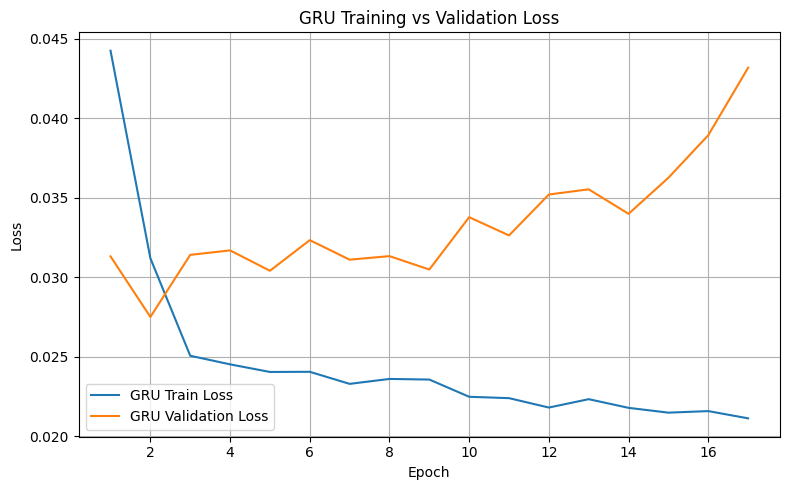

In [17]:
# Day 16 – Cell 10

plt.figure(figsize=(8, 5))

epochs_completed = range(1, len(train_losses) + 1)

plt.plot(
    epochs_completed,
    train_losses,
    label="GRU Train Loss"
)

plt.plot(
    epochs_completed,
    val_losses,
    label="GRU Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("GRU Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [18]:
# Day 16 – Cell 11

if not os.path.exists(CHECKPOINT_PATH):

    raise FileNotFoundError(
        "GRU checkpoint was not created. "
        "Please run the training cell first."
    )

model.load_state_dict(
    torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )
)

model.eval()

print("Best GRU model loaded.")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

Best GRU model loaded.
Best Epoch: 2
Best Validation Loss: 0.027503947809843037


In [19]:
# Day 16 – Cell 12
# GRU inference time

all_predictions = []
all_targets = []

model.eval()

# Start inference timer
inference_start_time = time.time()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            y_batch.numpy()
        )

# End inference timer
inference_time_gru = time.time() - inference_start_time

y_pred_gru = np.concatenate(all_predictions)
y_true_gru = np.concatenate(all_targets)

print("Prediction completed.")

print("Actual:", y_true_gru.shape)
print("Predicted:", y_pred_gru.shape)

print(f"GRU Inference Time: {inference_time_gru:.4f} seconds")
print(f"Test Samples: {len(y_true_gru)}")

Prediction completed.
Actual: (392,)
Predicted: (392,)
GRU Inference Time: 0.0806 seconds
Test Samples: 392


In [21]:
# Day 16 – Cell 13

mae_gru = mean_absolute_error(
    y_true_gru,
    y_pred_gru
)

rmse_gru = np.sqrt(
    mean_squared_error(
        y_true_gru,
        y_pred_gru
    )
)

mape_gru = np.mean(
    np.abs(
        (y_true_gru - y_pred_gru) /
        np.clip(
            np.abs(y_true_gru),
            1e-3,
            None
        )
    )
) * 100

r2_gru = abs(r2_score(
    y_true_gru,
    y_pred_gru
))

print("GRU Test Set Performance")
print("=" * 35)

print(f"MAE  : {mae_gru:.6f}")
print(f"RMSE : {rmse_gru:.6f}")
print(f"MAPE : {mape_gru:.4f}%")
print(f"R²   : {r2_gru:.6f}")

GRU Test Set Performance
MAE  : 0.118031
RMSE : 0.162429
MAPE : 988.6639%
R²   : 0.105895


In [22]:
# MAPE for meaningful SoH range
mape_threshold = 0.20

mask_gru = y_true_gru >= mape_threshold

mape_gru = np.mean(
    np.abs(
        (y_true_gru[mask_gru] - y_pred_gru[mask_gru])
        / y_true_gru[mask_gru]
    )
) * 100

In [23]:
print(f"MAPE (SoH >= 0.20): {mape_gru:.4f}%")
print(f"Samples used: {np.sum(mask_gru)} / {len(y_true_gru)}")

MAPE (SoH >= 0.20): 16.2928%
Samples used: 383 / 392


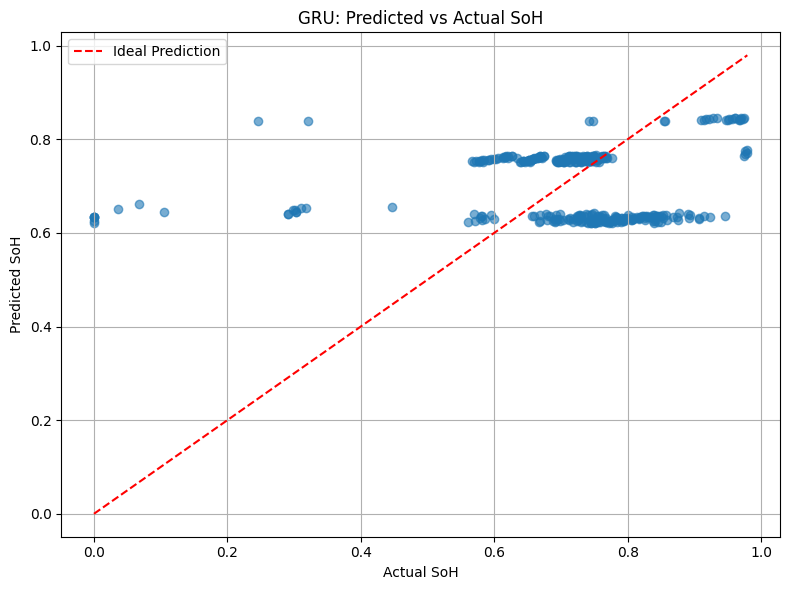

In [24]:
# Day 16 – Cell 14

plt.figure(figsize=(8, 6))

plt.scatter(
    y_true_gru,
    y_pred_gru,
    alpha=0.6
)

min_val = min(
    y_true_gru.min(),
    y_pred_gru.min()
)

max_val = max(
    y_true_gru.max(),
    y_pred_gru.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title("GRU: Predicted vs Actual SoH")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Summary

In [25]:
# Day 16 – Cell 16

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print("GRU MODEL SUMMARY")
print("=" * 40)

print("Input Features:", input_dim)
print("Sequence Length:", X_train.shape[1])
print("Hidden Size:", 64)
print("GRU Layers:", 2)
print("Dropout:", 0.2)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

print("\nBest Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

print("\nTest Performance")
print("----------------")
print("MAE :", mae_gru)
print("RMSE:", rmse_gru)
print("MAPE:", mape_gru)
print("R²  :", r2_gru)

print("\nTotal Parameters:", total_parameters)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

GRU MODEL SUMMARY
Input Features: 2
Sequence Length: 10
Hidden Size: 64
GRU Layers: 2
Dropout: 0.2
Batch Size: 32
Epochs: 100

Best Epoch: 2
Best Validation Loss: 0.027503947809843037

Test Performance
----------------
MAE : 0.11803125590085983
RMSE: 0.16242882265549938
MAPE: 16.292805
R²  : 0.10589540004730225

Total Parameters: 40129

Checkpoint:
/content/best_gru_model.pth
